(6, 4689467)


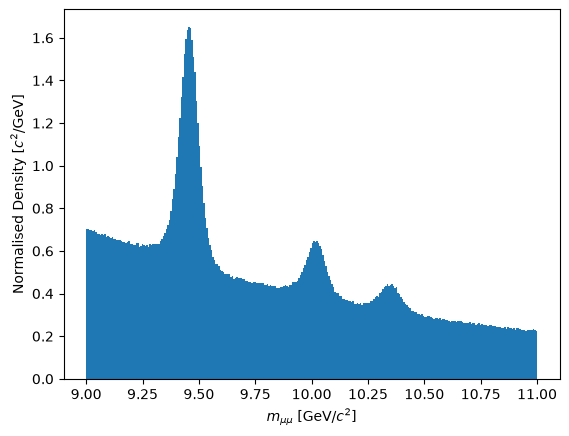

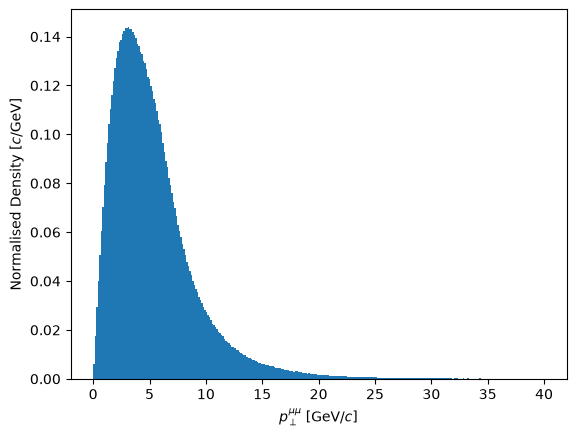

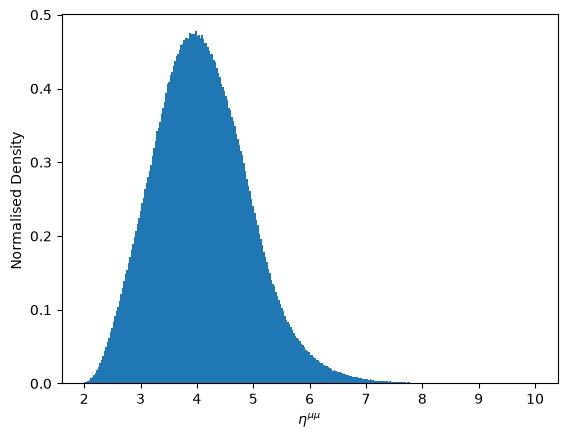

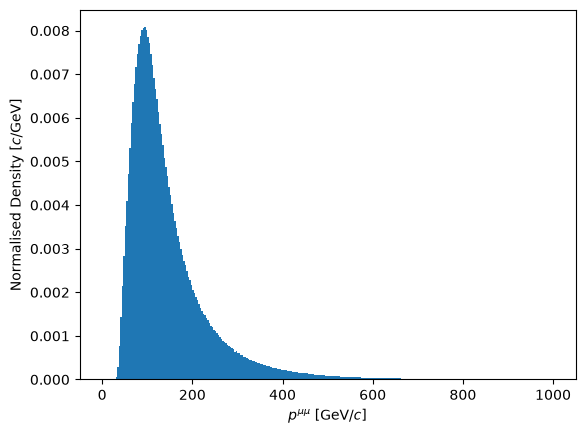

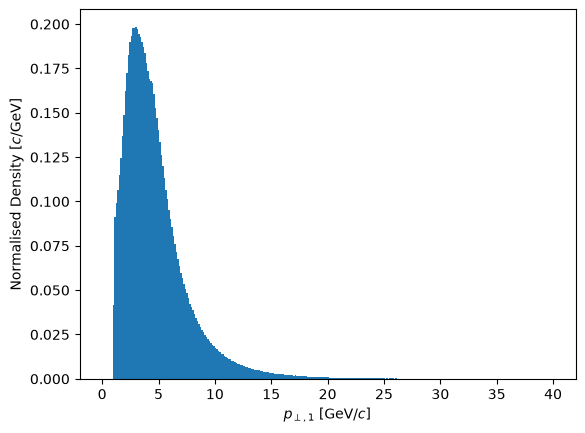

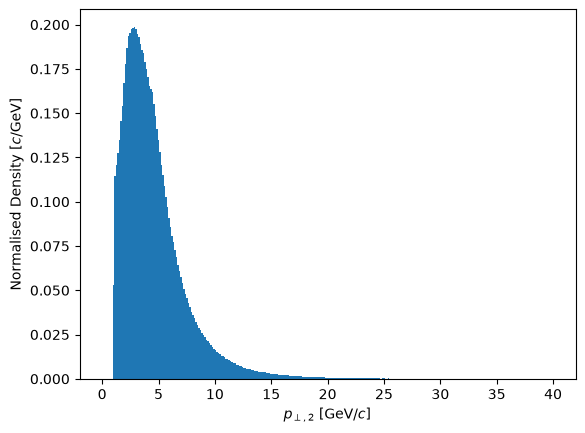

In [16]:
import numpy as np
import matplotlib.pyplot as plt

dataset = ['ups-15.bin','ups-15-small.bin','mc.bin']
filename = dataset[0]
with open(filename,'r') as f:
    datalist=np.fromfile(f,dtype=np.float32)

nevent = int(len(datalist)/6)
xdata_raw = np.split(datalist,nevent)

xdata = []
features = ['m_pair','pT_pair','eta','p_pair','pT_1','pT_2']
features_latex = [r'$m_{\mu\mu}$',r'$p_{\perp}^{\mu\mu}$'
                        ,r'$\eta^{\mu\mu}$',r'$p^{\mu\mu}$',r'$p_{\perp,1}$',r'$p_{\perp,2}$']
features_xaxis_label = [r'$m_{\mu\mu}$ [GeV/$c^2$]',r'$p_{\perp}^{\mu\mu}$ [GeV/$c$]'
                        ,r'$\eta^{\mu\mu}$',r'$p^{\mu\mu}$ [GeV/$c$]',r'$p_{\perp,1}$ [GeV/$c$]',r'$p_{\perp,2}$ [GeV/$c$]']
features_yaxis_label_unit = [r'[$c^2$/GeV]',r'[$c$/GeV]','',r'[$c$/GeV]',r'[$c$/GeV]',r'[$c$/GeV]']
features_range = [(9,11),(0,40),(2,10),(0,1000),(0,40),(0,40)]
for i in range(len(features)):
    feat_data = []
    for j in range(nevent):
        feat_data.append(xdata_raw[j][i])
    xdata.append(feat_data)

xdata = np.array(xdata)
print(xdata.shape)

for i in range(len(features)):
    plt.hist(xdata[i],bins=300,density=True,range=features_range[i])
    plt.xlabel(features_xaxis_label[i])
    plt.ylabel(f'Normalised Density {features_yaxis_label_unit[i]}')
    plt.show()

Upsilon(1S) Mass (mu): 9.45588 +- 0.00010 GeV/c^2
Mass Resolution (sigma): 0.04316 +- 0.00011 GeV/c^2
Exponential Slope (lmda): 0.58673 +- 0.00348
Signal Fraction (f): 0.20947 +- 0.00047
Upsilon(1S) Yield: 541080 +- 1214 events


Text(0.5, 1.0, '$\\Upsilon(1S)$ Peak')

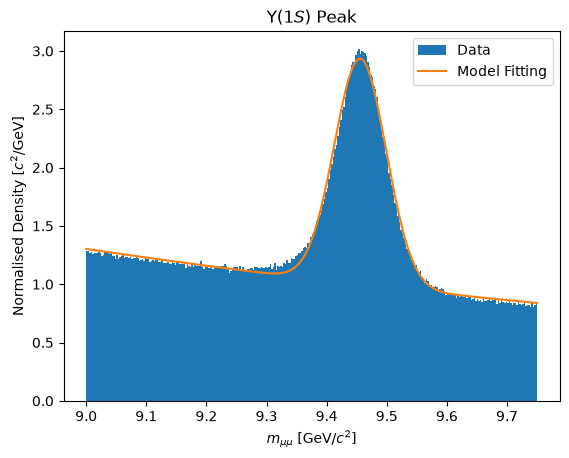

In [7]:
'''
Task 2: evaluate first peak using maximum likelihood fit
Minuit used, unbinned fit
'''

from scipy.special import erf
from iminuit import Minuit

min_mass,max_mass = 9.00,9.75
muon_pair_mass = xdata[0]
muon_pair_mass = muon_pair_mass[(muon_pair_mass > features_range[0][0]) & (muon_pair_mass < features_range[0][1])]
first_peak = muon_pair_mass[(muon_pair_mass > min_mass) & (muon_pair_mass < max_mass)]
N_tot = len(first_peak)

def upsilon_peak_model(x,mu,sigma,lmda,f):
    norm = 0.5* (erf((max_mass-mu)/(np.sqrt(2)*sigma)) - erf((min_mass-mu)/(np.sqrt(2)*sigma)))
    gaussian_pdf = 1 / np.sqrt(2*np.pi*sigma**2) * np.exp(-(x-mu)**2/(2*sigma**2)) / norm
    background_pdf = lmda * np.exp(-lmda * x) / (np.exp(-lmda * min_mass) - np.exp(-lmda * max_mass))
    return f*gaussian_pdf + (1-f)*background_pdf

def nll(mu,sigma,lmda,f):
    pdf = upsilon_peak_model(first_peak,mu,sigma,lmda,f)
    if np.any(pdf <= 0):
        return 1e10

    return -np.sum(np.log(pdf))


init_params = [9.4, 0.1, 1, 0.5]
bounds = [(min_mass,max_mass), (0.01, 1), (0.01, 10.0), (0.0, 1.0)]

res = Minuit(nll, *init_params)
res.limits = bounds
res.errordef = Minuit.LIKELIHOOD
res.migrad()
res.hesse()

mu_fit, sigma_fit, lmda_fit, f_fit = res.values
cov_matrix = np.array(res.covariance)
errors = res.errors
mu_err, sigma_err, lmda_err, f_err = errors

N_sig = f_fit * N_tot
N_sig_err = f_err * N_tot


print(f"Upsilon(1S) Mass (mu): {mu_fit:.5f} +- {mu_err:.5f} GeV/c^2")
print(f"Mass Resolution (sigma): {sigma_fit:.5f} +- {sigma_err:.5f} GeV/c^2")
print(f"Exponential Slope (lmda): {lmda_fit:.5f} +- {lmda_err:.5f}")
print(f"Signal Fraction (f): {f_fit:.5f} +- {f_err:.5f}")
print(f"Upsilon(1S) Yield: {N_sig:.0f} +- {N_sig_err:.0f} events")

xgrid = np.linspace(min_mass,max_mass,1000)
plt.hist(first_peak,bins=300,density=True,range=(min_mass,max_mass), label='Data')
plt.plot(xgrid,upsilon_peak_model(xgrid,mu_fit,sigma_fit,lmda_fit,f_fit), label='Model Fitting')
plt.legend()
plt.xlabel(features_xaxis_label[0])
plt.ylabel(f'Normalised Density {features_yaxis_label_unit[0]}')
plt.title(r'$\Upsilon(1S)$ Peak')

In [8]:
'''
Task 3: evaluate peaks on entire range
Unbinned NLL
'''

if filename != dataset[0]:
    min_mass_1, max_mass_1 = 9.00,9.75
    min_mass_2, max_mass_2 = 9.75,10.10
    min_mass_3, max_mass_3 = 10.10,10.50

    N_tot = len(muon_pair_mass)

    def composite_upsilon_peak_model(x,mu_1,sigma_1,mu_2,sigma_2,mu_3,sigma_3,lmda,f_1,f_2,f_3):
        min_mass, max_mass = features_range[0][0],features_range[0][1]
        norm_1 = 0.5* (erf((max_mass-mu_1)/(np.sqrt(2)*sigma_1)) - erf((min_mass-mu_1)/(np.sqrt(2)*sigma_1)))
        norm_2 = 0.5* (erf((max_mass-mu_2)/(np.sqrt(2)*sigma_2)) - erf((min_mass-mu_2)/(np.sqrt(2)*sigma_2)))
        norm_3 = 0.5* (erf((max_mass-mu_3)/(np.sqrt(2)*sigma_3)) - erf((min_mass-mu_3)/(np.sqrt(2)*sigma_3)))
        gaussian_pdf_1 = 1 / np.sqrt(2*np.pi*sigma_1**2) * np.exp(-(x-mu_1)**2/(2*sigma_1**2)) / norm_1
        gaussian_pdf_2 = 1 / np.sqrt(2*np.pi*sigma_2**2) * np.exp(-(x-mu_2)**2/(2*sigma_2**2)) / norm_2
        gaussian_pdf_3 = 1 / np.sqrt(2*np.pi*sigma_3**2) * np.exp(-(x-mu_3)**2/(2*sigma_3**2)) / norm_3
        background_pdf = lmda * np.exp(-lmda * x) / (np.exp(-lmda * features_range[0][0]) - np.exp(-lmda * features_range[0][1]))
        return f_1*gaussian_pdf_1 + f_2*gaussian_pdf_2 + f_3*gaussian_pdf_3 + (1-f_1-f_2-f_3)*background_pdf

    def nll_composite(mu_1,sigma_1,mu_2,sigma_2,mu_3,sigma_3,lmda,f_1,f_2,f_3):
        pdf = composite_upsilon_peak_model(muon_pair_mass,mu_1,sigma_1,mu_2,sigma_2,mu_3,sigma_3,lmda,f_1,f_2,f_3)
        if np.any(pdf <= 0):
            return 1e10

        return -np.sum(np.log(pdf))


    init_params = [9.45, 0.043, 10.02, 0.046, 10.35, 0.04, 0.58, 0.12, 0.03, 0.01]
    bounds = [(min_mass_1,max_mass_1), (0.01, 1), (min_mass_2,max_mass_2), (0.01, 1), (min_mass_3,max_mass_3), (0.01, 1), (0.01, 10.0), (0.0, 1.0), (0.0, 1.0), (0.0, 1.0)]

    res = Minuit(nll_composite, *init_params)
    res.limits = bounds
    res.errordef = Minuit.LIKELIHOOD
    res.strategy = 0
    res.tol = 1.0
    res.migrad()
    res.hesse()

    mu_1_fit, sigma_1_fit, mu_2_fit, sigma_2_fit, mu_3_fit, sigma_3_fit, lmda_fit, f_1_fit, f_2_fit, f_3_fit = res.values
    cov_matrix = np.array(res.covariance)
    errors = res.errors
    mu_1_err, sigma_1_err, mu_2_err, sigma_2_err, mu_3_err, sigma_3_err, lmda_err, f_1_err, f_2_err, f_3_err = errors

    N_sig_1 = f_1_fit * N_tot
    N_sig_1_err = f_1_err * N_tot
    N_sig_2 = f_2_fit * N_tot
    N_sig_2_err = f_2_err * N_tot
    N_sig_3 = f_3_fit * N_tot
    N_sig_3_err = f_3_err * N_tot



    print(f"Upsilon(1S) Mass (mu_1): {mu_1_fit:.5f} +- {mu_1_err:.5f} GeV/c^2")
    print(f"Mass Resolution (sigma_1): {sigma_1_fit:.5f} +- {sigma_1_err:.5f} GeV/c^2")
    print(f"Signal Fraction (f_1): {f_1_fit:.5f} +- {f_1_err:.5f}")
    print(f"Upsilon(1S) Yield (N_sig_1): {N_sig_1:.0f} +- {N_sig_1_err:.0f} events")
    print(f"-----------------------------------------------------------")
    print(f"Upsilon(2S) Mass (mu_2): {mu_2_fit:.5f} +- {mu_2_err:.5f} GeV/c^2")
    print(f"Mass Resolution (sigma_2): {sigma_2_fit:.5f} +- {sigma_2_err:.5f} GeV/c^2")
    print(f"Signal Fraction (f_2): {f_2_fit:.5f} +- {f_2_err:.5f}")
    print(f"Upsilon(2S) Yield (N_sig_2): {N_sig_2:.0f} +- {N_sig_2_err:.0f} events")
    print(f"-----------------------------------------------------------")
    print(f"Upsilon(3S) Mass (mu_3): {mu_3_fit:.5f} +- {mu_3_err:.5f} GeV/c^2")
    print(f"Mass Resolution (sigma_3): {sigma_3_fit:.5f} +- {sigma_3_err:.5f} GeV/c^2")
    print(f"Signal Fraction (f_3): {f_3_fit:.5f} +- {f_3_err:.5f}")
    print(f"Upsilon(3S) Yield (N_sig_3): {N_sig_3:.0f} +- {N_sig_3_err:.0f} events")
    print(f"-----------------------------------------------------------")
    print(f"Exponential Slope (lmda): {lmda_fit:.5f} +- {lmda_err:.5f}")

    xgrid = np.linspace(features_range[0][0],features_range[0][1],1000)
    plt.hist(muon_pair_mass,bins=300,density=True,range=(features_range[0][0],features_range[0][1]),label='Data')
    plt.plot(xgrid,composite_upsilon_peak_model(xgrid,mu_1_fit,sigma_1_fit,mu_2_fit,sigma_2_fit,mu_3_fit,sigma_3_fit,lmda_fit,f_1_fit,f_2_fit,f_3_fit), label='Model Fitting')
    plt.legend()
    plt.xlabel(features_xaxis_label[0])
    plt.ylabel(f'Normalised Density {features_yaxis_label_unit[0]}')
    plt.title(r'$\Upsilon$-Meson Peaks')

Upsilon(1S) Mass (mu_1): 9.4558459 +- 0.0000999 GeV/c^2
Mass Resolution (sigma_1): 0.0433790 +- 0.0001015 GeV/c^2
Signal Fraction (f_1): 0.1160446 +- 0.0002425
Upsilon(1S) Yield (N_sig_1): 544187 +- 1137 events
-----------------------------------------------------------
Upsilon(2S) Mass (mu_2): 10.0188032 +- 0.0002998 GeV/c^2
Mass Resolution (sigma_2): 0.0444568 +- 0.0003153 GeV/c^2
Signal Fraction (f_2): 0.0276012 +- 0.0001747
Upsilon(2S) Yield (N_sig_2): 129435 +- 819 events
-----------------------------------------------------------
Upsilon(3S) Mass (mu_3): 10.3502070 +- 0.0005627 GeV/c^2
Mass Resolution (sigma_3): 0.0455929 +- 0.0005570 GeV/c^2
Signal Fraction (f_3): 0.0134435 +- 0.0001498
Upsilon(3S) Yield (N_sig_3): 63043 +- 702 events
-----------------------------------------------------------
Exponential Slope (lmda): 0.5799315 +- 0.0000006


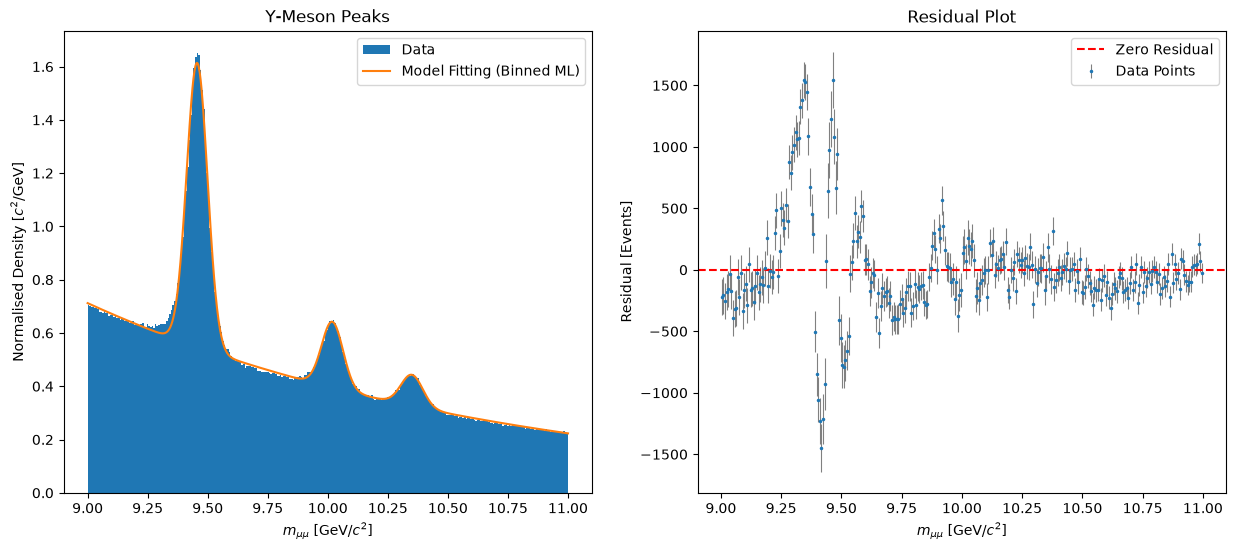

Chi2 value: 2145.878
Reduced Chi2: 7.400
Birge Ratio: 2.720


In [9]:
'''
Task 3: evaluate peaks on entire range
Binned NLL

Task 4: Residual Plot
'''
from iminuit.cost import BinnedNLL

muon_pair_mass = xdata[0]
muon_pair_mass = muon_pair_mass[(muon_pair_mass > features_range[0][0]) & (muon_pair_mass < features_range[0][1])]
min_mass, max_mass = features_range[0][0],features_range[0][1]
min_mass_1, max_mass_1 = 9.00,9.75
min_mass_2, max_mass_2 = 9.75,10.10
min_mass_3, max_mass_3 = 10.10,10.50

n_bins = 300
counts, bin_edges = np.histogram(muon_pair_mass, bins=n_bins, range=(min_mass, max_mass))
bin_width = (max_mass - min_mass) / n_bins
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
N_tot = len(muon_pair_mass)


def composite_upsilon_cdf(x,mu_1,sigma_1,mu_2,sigma_2,mu_3,sigma_3,lmda,f_1,f_2,f_3):

    def gaussian_cdf(m,mu,sigma):
        norm = 0.5* (erf((max_mass-mu)/(np.sqrt(2)*sigma)) - erf((min_mass-mu)/(np.sqrt(2)*sigma)))
        return 0.5*(erf((m-mu)/(np.sqrt(2)*sigma)) - erf((min_mass-mu)/(np.sqrt(2)*sigma))) / norm

    background_cdf = (np.exp(-lmda * min_mass) - np.exp(-lmda * x)) / (np.exp(-lmda * min_mass) - np.exp(-lmda * max_mass))
    return f_1*gaussian_cdf(x,mu_1,sigma_1) + f_2*gaussian_cdf(x,mu_2,sigma_2) + f_3*gaussian_cdf(x,mu_3,sigma_3) + (1-f_1-f_2-f_3)*background_cdf

# def nll_composite(mu_1,sigma_1,mu_2,sigma_2,mu_3,sigma_3,lmda,f_1,f_2,f_3):
#     pdf = composite_upsilon_peak_model(muon_pair_mass,mu_1,sigma_1,mu_2,sigma_2,mu_3,sigma_3,lmda,f_1,f_2,f_3)
#     if np.any(pdf <= 0):
#         return 1e10

#     return -np.sum(np.log(pdf))


init_params = [9.45, 0.043, 10.02, 0.046, 10.35, 0.04, 0.58, 0.12, 0.03, 0.01]
bounds = [(min_mass_1,max_mass_1), (0.01, 1), (min_mass_2,max_mass_2), (0.01, 1), (min_mass_3,max_mass_3), (0.01, 1), (0.01, 10.0), (0.0, 1.0), (0.0, 1.0), (0.0, 1.0)]
cost = BinnedNLL(counts, bin_edges, composite_upsilon_cdf)

res = Minuit(cost, *init_params)
res.limits = bounds
res.migrad()
res.hesse()

mu_1_fit, sigma_1_fit, mu_2_fit, sigma_2_fit, mu_3_fit, sigma_3_fit, lmda_fit, f_1_fit, f_2_fit, f_3_fit = res.values
cov_matrix = np.array(res.covariance)
errors = res.errors
mu_1_err, sigma_1_err, mu_2_err, sigma_2_err, mu_3_err, sigma_3_err, lmda_err, f_1_err, f_2_err, f_3_err = errors

N_sig_1 = f_1_fit * N_tot
N_sig_1_err = f_1_err * N_tot
N_sig_2 = f_2_fit * N_tot
N_sig_2_err = f_2_err * N_tot
N_sig_3 = f_3_fit * N_tot
N_sig_3_err = f_3_err * N_tot



print(f"Upsilon(1S) Mass (mu_1): {mu_1_fit:.7f} +- {mu_1_err:.7f} GeV/c^2")
print(f"Mass Resolution (sigma_1): {sigma_1_fit:.7f} +- {sigma_1_err:.7f} GeV/c^2")
print(f"Signal Fraction (f_1): {f_1_fit:.7f} +- {f_1_err:.7f}")
print(f"Upsilon(1S) Yield (N_sig_1): {N_sig_1:.0f} +- {N_sig_1_err:.0f} events")
print(f"-----------------------------------------------------------")
print(f"Upsilon(2S) Mass (mu_2): {mu_2_fit:.7f} +- {mu_2_err:.7f} GeV/c^2")
print(f"Mass Resolution (sigma_2): {sigma_2_fit:.7f} +- {sigma_2_err:.7f} GeV/c^2")
print(f"Signal Fraction (f_2): {f_2_fit:.7f} +- {f_2_err:.7f}")
print(f"Upsilon(2S) Yield (N_sig_2): {N_sig_2:.0f} +- {N_sig_2_err:.0f} events")
print(f"-----------------------------------------------------------")
print(f"Upsilon(3S) Mass (mu_3): {mu_3_fit:.7f} +- {mu_3_err:.7f} GeV/c^2")
print(f"Mass Resolution (sigma_3): {sigma_3_fit:.7f} +- {sigma_3_err:.7f} GeV/c^2")
print(f"Signal Fraction (f_3): {f_3_fit:.7f} +- {f_3_err:.7f}")
print(f"Upsilon(3S) Yield (N_sig_3): {N_sig_3:.0f} +- {N_sig_3_err:.0f} events")
print(f"-----------------------------------------------------------")
print(f"Exponential Slope (lmda): {lmda_fit:.7f} +- {lmda_err:.7f}")

fig, (ax1,ax2) = plt.subplots(1,2,figsize=(15,6))

expected_cdf = composite_upsilon_cdf(bin_edges, *res.values)
expected_counts = np.diff(expected_cdf) * N_tot
residual = counts - expected_counts
yerr = np.sqrt(counts)

xgrid = np.linspace(features_range[0][0],features_range[0][1],1000)
ax1.hist(muon_pair_mass,bins=300,density=True,range=(features_range[0][0],features_range[0][1]),label='Data')
dx=1e-5
pdf_grid = (composite_upsilon_cdf(xgrid + dx, *res.values) - composite_upsilon_cdf(xgrid - dx, *res.values)) / (2*dx)
ax1.plot(xgrid,pdf_grid, label='Model Fitting (Binned ML)')
ax1.legend()
ax1.set_xlabel(features_xaxis_label[0])
ax1.set_ylabel(f'Normalised Density {features_yaxis_label_unit[0]}')
ax1.set_title(r'$\Upsilon$-Meson Peaks')

ax2.errorbar(bin_centers, residual, yerr=yerr, fmt="o", markersize=1.5, ecolor="gray", elinewidth=0.8,label='Data Points')
ax2.axhline(0, color="red", linestyle="--",label='Zero Residual')
ax2.set_xlabel(features_xaxis_label[0])
ax2.set_ylabel(f"Residual [Events]")
ax2.legend()
ax2.set_title(r'Residual Plot')
plt.savefig(f'whole_spectrum_fit_binned_{filename[:-4]}.pdf')
plt.show()

chi2 = np.sum(residual**2/expected_counts)
reduced_chi2 = chi2 / (len(counts) - len(init_params))
BR = np.sqrt(reduced_chi2)
print(f'Chi2 value: {chi2:.3f}')
print(f'Reduced Chi2: {reduced_chi2:.3f}')
print(f'Birge Ratio: {BR:.3f}')

In [10]:
'''
Task 5: Enhance Model
Two-Gaussian sum on mc.bin

skewness test shows that two-gaussian sum is not suitable for a skewed distribution
'''
from scipy.stats import skew, skewtest

if filename == dataset[2]:
    min_mass,max_mass = 9.00,9.75
    muon_pair_mass = xdata[0]
    muon_pair_mass = muon_pair_mass[(muon_pair_mass > features_range[0][0]) & (muon_pair_mass < features_range[0][1])]
    first_peak = muon_pair_mass[(muon_pair_mass > min_mass) & (muon_pair_mass < max_mass)]
    N_tot = len(first_peak)

    def two_gaussian_model(x,mu,sigma_1,sigma_2,f):
        norm_1 = 0.5* (erf((max_mass-mu)/(np.sqrt(2)*sigma_1)) - erf((min_mass-mu)/(np.sqrt(2)*sigma_1)))
        norm_2 = 0.5* (erf((max_mass-mu)/(np.sqrt(2)*sigma_2)) - erf((min_mass-mu)/(np.sqrt(2)*sigma_2)))
        gaussian_pdf_1 = 1 / np.sqrt(2*np.pi*sigma_1**2) * np.exp(-(x-mu)**2/(2*sigma_1**2)) / norm_1
        gaussian_pdf_2 = 1 / np.sqrt(2*np.pi*sigma_2**2) * np.exp(-(x-mu)**2/(2*sigma_2**2)) / norm_2
        return f*gaussian_pdf_1 + (1-f)*gaussian_pdf_2

    def nll(mu,sigma_1,sigma_2,f):
        pdf = two_gaussian_model(first_peak,mu,sigma_1,sigma_2,f)
        if np.any(pdf <= 0):
            return 1e10

        return -np.sum(np.log(pdf))


    init_params = [9.4, 0.04,0.1, 0.8]
    bounds = [(min_mass,max_mass), (0.001, 1), (0.01, 1), (0.0, 1.0)]

    res = Minuit(nll, *init_params)
    res.limits = bounds
    res.errordef = Minuit.LIKELIHOOD
    res.migrad()
    res.hesse()

    mu_fit, sigma_1_fit, sigma_2_fit, f_fit = res.values
    cov_matrix = np.array(res.covariance)
    errors = res.errors
    mu_err, sigma_1_err, sigma_2_err, f_err = errors



    print(f"Upsilon(1S) Mass (mu): {mu_fit:.5f} +- {mu_err:.5f} GeV/c^2")
    print(f"Wide Gaussian Component (sigma_2): {sigma_2_fit:.5f} +- {sigma_2_err:.5f} GeV/c^2")
    print(f"Narrow Gaussian Component (sigma_1): {sigma_1_fit:.5f} +- {sigma_1_err:.5f} GeV/c^2")
    print(f"Narrow Component Fraction (f): {f_fit:.5f} +- {f_err:.5f}")

    xgrid = np.linspace(min_mass,max_mass,1000)
    plt.hist(first_peak,bins=300,density=True,range=(min_mass,max_mass), label='Data')
    plt.plot(xgrid,two_gaussian_model(xgrid,*res.values), label='Model Fitting')
    plt.legend()
    plt.xlabel(features_xaxis_label[0])
    plt.ylabel(f'Normalised Density {features_yaxis_label_unit[0]}')
    plt.title(r'$\Upsilon(1S)$ Peak Fitted by Two-Gaussian Sum')
    plt.savefig(f'ups_1s_twogaussian_{filename[:-4]}.pdf')
    plt.show()

    gamma_1 = skew(first_peak)
    se_gamma = np.sqrt(6.0 / len(first_peak))
    z_score = gamma_1 / se_gamma
    print(f"Skewness: {gamma_1:.4f}")
    print(f"Standard Error: {se_gamma:.4f}")
    print(f"z-score: {z_score:.1f}")
    stat, p_val = skewtest(first_peak)
    print(f"p-value: {p_val:.2e}")

Upsilon(1S) Mass (mu_1): 9.4561772 +- 0.0000993 GeV/c^2
Mass Resolution (sigma_1): 0.0430536 +- 0.0001031 GeV/c^2
Signal Fraction (f_1): 0.1242970 +- 0.0002570
Upsilon(1S) Yield (N_sig_1): 582887 +- 1205 events
-----------------------------------------------------------
Upsilon(2S) Mass (mu_2): 10.0188376 +- 0.0003027 GeV/c^2
Mass Resolution (sigma_2): 0.0450531 +- 0.0003249 GeV/c^2
Signal Fraction (f_2): 0.0310493 +- 0.0001919
Upsilon(2S) Yield (N_sig_2): 145605 +- 900 events
-----------------------------------------------------------
Upsilon(3S) Mass (mu_3): 10.3501789 +- 0.0005577 GeV/c^2
Mass Resolution (sigma_3): 0.0485479 +- 0.0005959 GeV/c^2
Signal Fraction (f_3): 0.0161987 +- 0.0001714
Upsilon(3S) Yield (N_sig_3): 75963 +- 804 events
-----------------------------------------------------------
Exponential Slope (lmda): 0.5800140 +- 0.0000006
Purity: 0.172


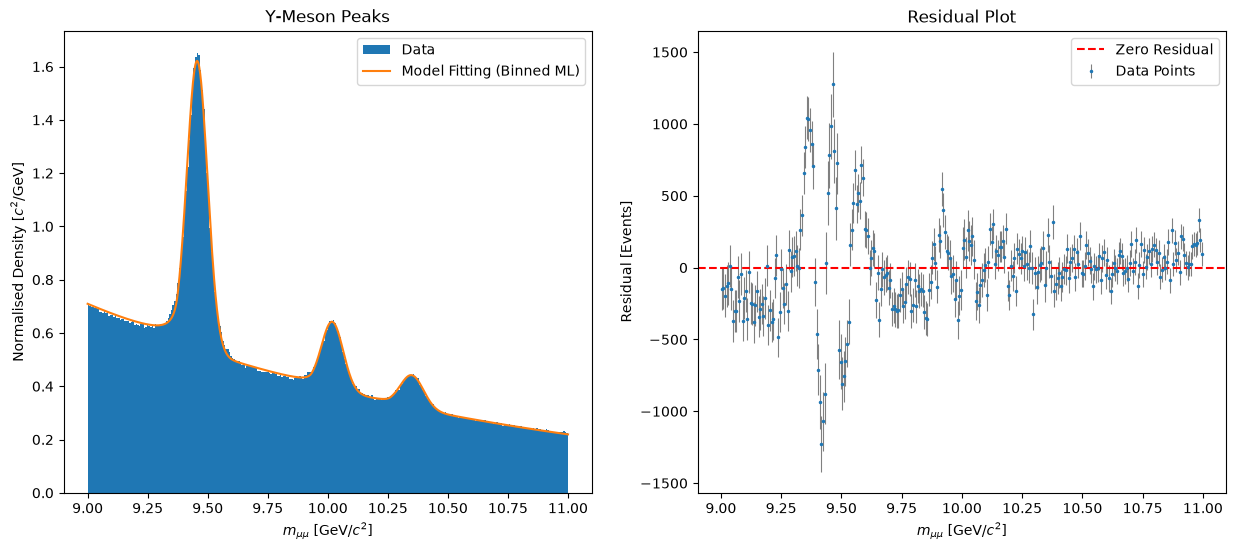

Chi2 value: 1266.604
Reduced Chi2: 4.368
Birge Ratio: 2.090


In [21]:
'''
Task 5: Fit enhanced model over entire spectrum (Crystal Ball Function)
'''
from scipy.stats import crystalball
from iminuit.cost import BinnedNLL

muon_pair_mass = xdata[0]
muon_pair_mass = muon_pair_mass[(muon_pair_mass > features_range[0][0]) & (muon_pair_mass < features_range[0][1])]
min_mass, max_mass = features_range[0][0],features_range[0][1]
min_mass_1, max_mass_1 = 9.00,9.75
min_mass_2, max_mass_2 = 9.75,10.10
min_mass_3, max_mass_3 = 10.10,10.50

n_bins = 300
counts, bin_edges = np.histogram(muon_pair_mass, bins=n_bins, range=(min_mass, max_mass))
bin_width = (max_mass - min_mass) / n_bins
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
N_tot = len(muon_pair_mass)

alpha = 1.89471
n = 1.09539


def composite_upsilon_cbf_cdf(x,mu_1,sigma_1,mu_2,sigma_2,mu_3,sigma_3,lmda,f_1,f_2,f_3):

    def crystal_ball_cdf(x, mu, sigma):
        norm = crystalball.cdf(max_mass, beta=alpha, m=n, loc=mu, scale=sigma) - crystalball.cdf(min_mass, beta=alpha, m=n, loc=mu, scale=sigma)
        return (crystalball.cdf(x, beta=alpha, m=n, loc=mu, scale=sigma) - crystalball.cdf(min_mass, beta=alpha, m=n, loc=mu, scale=sigma)) / norm

    background_cdf = (np.exp(-lmda * min_mass) - np.exp(-lmda * x)) / (np.exp(-lmda * min_mass) - np.exp(-lmda * max_mass))
    return f_1*crystal_ball_cdf(x,mu_1,sigma_1) + f_2*crystal_ball_cdf(x,mu_2,sigma_2) + f_3*crystal_ball_cdf(x,mu_3,sigma_3) + (1-f_1-f_2-f_3)*background_cdf

# def nll_composite(mu_1,sigma_1,mu_2,sigma_2,mu_3,sigma_3,lmda,f_1,f_2,f_3):
#     pdf = composite_upsilon_peak_model(muon_pair_mass,mu_1,sigma_1,mu_2,sigma_2,mu_3,sigma_3,lmda,f_1,f_2,f_3)
#     if np.any(pdf <= 0):
#         return 1e10

#     return -np.sum(np.log(pdf))


init_params = [9.45, 0.043, 10.02, 0.046, 10.35, 0.04, 0.58, 0.12, 0.03, 0.01]
bounds = [(min_mass_1,max_mass_1), (0.01, 1), (min_mass_2,max_mass_2), (0.01, 1), (min_mass_3,max_mass_3), (0.01, 1), (0.01, 10.0), (0.0, 1.0), (0.0, 1.0), (0.0, 1.0)]
cost = BinnedNLL(counts, bin_edges, composite_upsilon_cbf_cdf)

res = Minuit(cost, *init_params)
res.limits = bounds
res.migrad()
res.hesse()

mu_1_fit, sigma_1_fit, mu_2_fit, sigma_2_fit, mu_3_fit, sigma_3_fit, lmda_fit, f_1_fit, f_2_fit, f_3_fit = res.values
cov_matrix = np.array(res.covariance)
errors = res.errors
mu_1_err, sigma_1_err, mu_2_err, sigma_2_err, mu_3_err, sigma_3_err, lmda_err, f_1_err, f_2_err, f_3_err = errors

N_sig_1 = f_1_fit * N_tot
N_sig_1_err = f_1_err * N_tot
N_sig_2 = f_2_fit * N_tot
N_sig_2_err = f_2_err * N_tot
N_sig_3 = f_3_fit * N_tot
N_sig_3_err = f_3_err * N_tot



print(f"Upsilon(1S) Mass (mu_1): {mu_1_fit:.7f} +- {mu_1_err:.7f} GeV/c^2")
print(f"Mass Resolution (sigma_1): {sigma_1_fit:.7f} +- {sigma_1_err:.7f} GeV/c^2")
print(f"Signal Fraction (f_1): {f_1_fit:.7f} +- {f_1_err:.7f}")
print(f"Upsilon(1S) Yield (N_sig_1): {N_sig_1:.0f} +- {N_sig_1_err:.0f} events")
print(f"-----------------------------------------------------------")
print(f"Upsilon(2S) Mass (mu_2): {mu_2_fit:.7f} +- {mu_2_err:.7f} GeV/c^2")
print(f"Mass Resolution (sigma_2): {sigma_2_fit:.7f} +- {sigma_2_err:.7f} GeV/c^2")
print(f"Signal Fraction (f_2): {f_2_fit:.7f} +- {f_2_err:.7f}")
print(f"Upsilon(2S) Yield (N_sig_2): {N_sig_2:.0f} +- {N_sig_2_err:.0f} events")
print(f"-----------------------------------------------------------")
print(f"Upsilon(3S) Mass (mu_3): {mu_3_fit:.7f} +- {mu_3_err:.7f} GeV/c^2")
print(f"Mass Resolution (sigma_3): {sigma_3_fit:.7f} +- {sigma_3_err:.7f} GeV/c^2")
print(f"Signal Fraction (f_3): {f_3_fit:.7f} +- {f_3_err:.7f}")
print(f"Upsilon(3S) Yield (N_sig_3): {N_sig_3:.0f} +- {N_sig_3_err:.0f} events")
print(f"-----------------------------------------------------------")
print(f"Exponential Slope (lmda): {lmda_fit:.7f} +- {lmda_err:.7f}")
print(f"Purity: {f_1_fit+f_2_fit+f_3_fit:.3f}")

fig, (ax1,ax2) = plt.subplots(1,2,figsize=(15,6))

expected_cdf = composite_upsilon_cbf_cdf(bin_edges, *res.values)
expected_counts = np.diff(expected_cdf) * N_tot
residual = counts - expected_counts
yerr = np.sqrt(counts)

xgrid = np.linspace(features_range[0][0],features_range[0][1],1000)
ax1.hist(muon_pair_mass,bins=300,density=True,range=(features_range[0][0],features_range[0][1]),label='Data')
dx=1e-5
pdf_grid = (composite_upsilon_cbf_cdf(xgrid + dx, *res.values) - composite_upsilon_cbf_cdf(xgrid - dx, *res.values)) / (2*dx)
ax1.plot(xgrid,pdf_grid, label='Model Fitting (Binned ML)')
ax1.legend()
ax1.set_xlabel(features_xaxis_label[0])
ax1.set_ylabel(f'Normalised Density {features_yaxis_label_unit[0]}')
ax1.set_title(r'$\Upsilon$-Meson Peaks')

ax2.errorbar(bin_centers, residual, yerr=yerr, fmt="o", markersize=1.5, ecolor="gray", elinewidth=0.8,label='Data Points')
ax2.axhline(0, color="red", linestyle="--",label='Zero Residual')
ax2.set_xlabel(features_xaxis_label[0])
ax2.set_ylabel(f"Residual [Events]")
ax2.legend()
ax2.set_title(r'Residual Plot')
plt.savefig(f'whole_spectrum_fit_binned_{filename[:-4]}.pdf')
plt.show()

chi2 = np.sum(residual**2/expected_counts)
reduced_chi2 = chi2 / (len(counts) - len(init_params))
BR = np.sqrt(reduced_chi2)
print(f'Chi2 value: {chi2:.3f}')
print(f'Reduced Chi2: {reduced_chi2:.3f}')
print(f'Birge Ratio: {BR:.3f}')

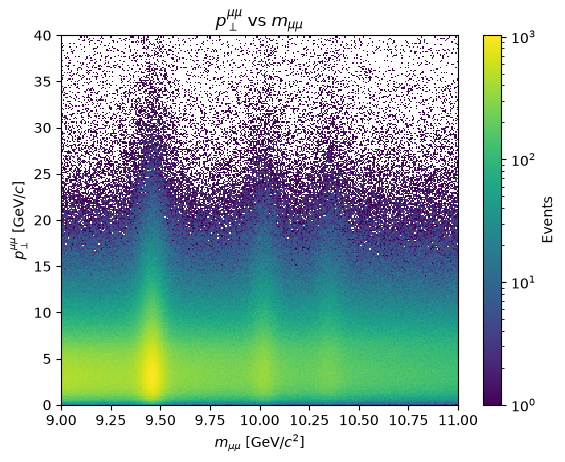

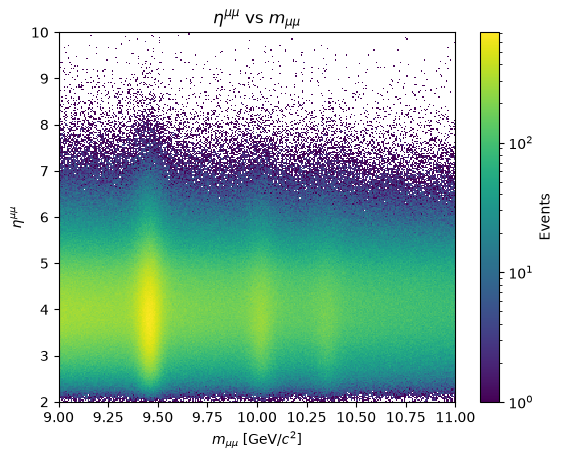

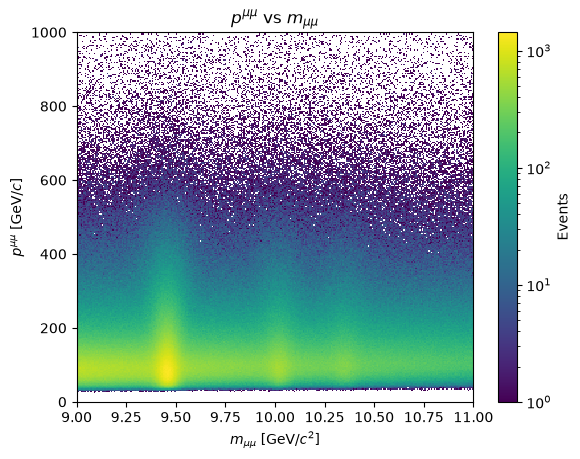

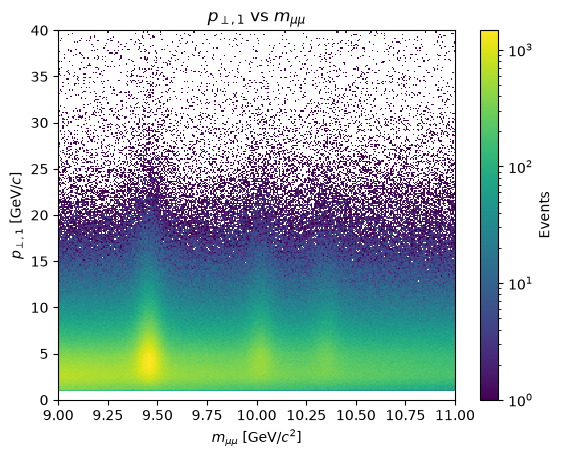

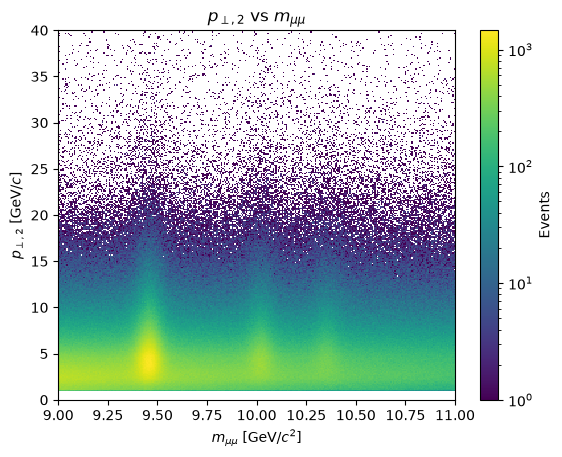

In [18]:
'''
Task 6: make 2d plots of additional observables vs muon pair mass
'''
import matplotlib.colors as colors
import matplotlib.pyplot as plt

for i in range(1,6):
    plt.hist2d(
        xdata[0],
        xdata[i],
        bins=[300, 300],
        range=[features_range[0],features_range[i]],
        cmap="viridis",
        norm=colors.LogNorm(),
    )
    plt.colorbar(label="Events")
    plt.xlabel(features_xaxis_label[0])
    plt.ylabel(features_xaxis_label[i])
    plt.title(f"{features_latex[i]} vs {features_latex[0]}")
    plt.show()

Upsilon(1S) Mass (mu_1): 9.4565715 +- 0.0001456 GeV/c^2
Mass Resolution (sigma_1): 0.0444388 +- 0.0001509 GeV/c^2
Signal Fraction (f_1): 0.1323918 +- 0.0003880
Upsilon(1S) Yield (N_sig_1): 274013 +- 803 events
-----------------------------------------------------------
Upsilon(2S) Mass (mu_2): 10.0188810 +- 0.0003963 GeV/c^2
Mass Resolution (sigma_2): 0.0477503 +- 0.0004296 GeV/c^2
Signal Fraction (f_2): 0.0397458 +- 0.0003053
Upsilon(2S) Yield (N_sig_2): 82263 +- 632 events
-----------------------------------------------------------
Upsilon(3S) Mass (mu_3): 10.3508571 +- 0.0006883 GeV/c^2
Mass Resolution (sigma_3): 0.0537120 +- 0.0007818 GeV/c^2
Signal Fraction (f_3): 0.0237810 +- 0.0002891
Upsilon(3S) Yield (N_sig_3): 49220 +- 598 events
-----------------------------------------------------------
Exponential Slope (lmda): 0.4816560 +- 0.0000008
Purity: 0.196


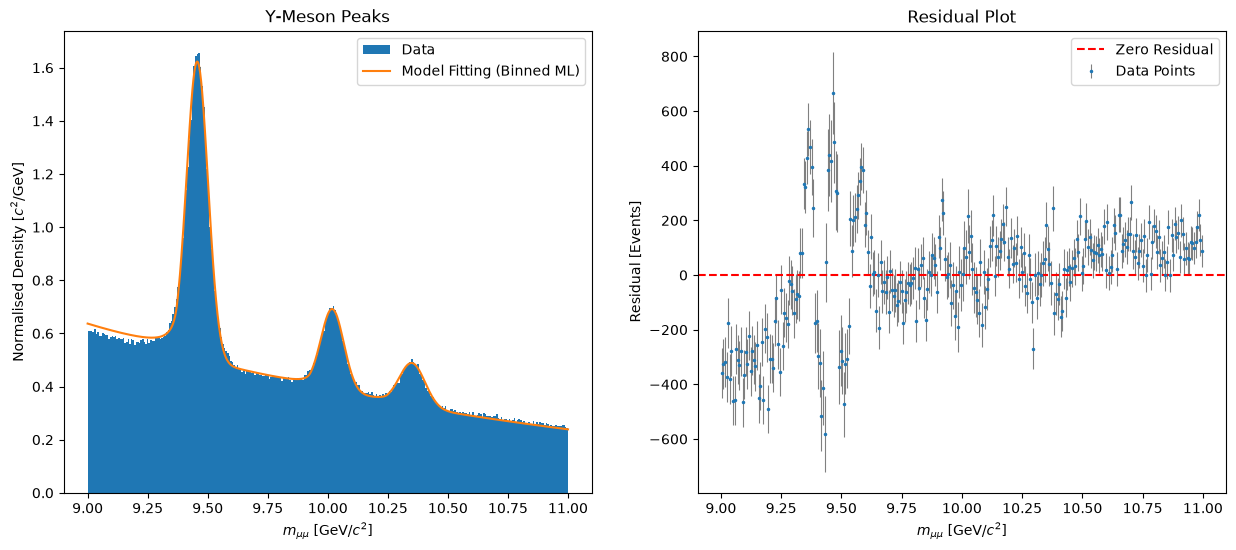

Chi2 value: 1454.043
Reduced Chi2: 5.014
Birge Ratio: 2.239


In [29]:
'''
Task 6: Threshold Cut to produce cleaner signal
'''
from iminuit.cost import BinnedNLL

muon_pair_mass = xdata[0]
p_T_mm = xdata[1]
muon_pair_mass = muon_pair_mass[(muon_pair_mass > features_range[0][0]) & (muon_pair_mass < features_range[0][1])]
cut_mass = muon_pair_mass[p_T_mm > 5]

min_mass, max_mass = features_range[0][0],features_range[0][1]
min_mass_1, max_mass_1 = 9.25,9.60
min_mass_2, max_mass_2 = 9.80,10.10
min_mass_3, max_mass_3 = 10.20,10.40

n_bins = 300
counts, bin_edges = np.histogram(cut_mass, bins=n_bins, range=(min_mass, max_mass))
bin_width = (max_mass - min_mass) / n_bins
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
N_tot = len(cut_mass)

alpha = 1.89471
n = 1.09539


def composite_upsilon_cbf_cdf(x,mu_1,sigma_1,mu_2,sigma_2,mu_3,sigma_3,lmda,f_1,f_2,f_3):

    def crystal_ball_cdf(x, mu, sigma):
        norm = crystalball.cdf(max_mass, beta=alpha, m=n, loc=mu, scale=sigma) - crystalball.cdf(min_mass, beta=alpha, m=n, loc=mu, scale=sigma)
        return (crystalball.cdf(x, beta=alpha, m=n, loc=mu, scale=sigma) - crystalball.cdf(min_mass, beta=alpha, m=n, loc=mu, scale=sigma)) / norm

    background_cdf = (np.exp(-lmda * min_mass) - np.exp(-lmda * x)) / (np.exp(-lmda * min_mass) - np.exp(-lmda * max_mass))
    return f_1*crystal_ball_cdf(x,mu_1,sigma_1) + f_2*crystal_ball_cdf(x,mu_2,sigma_2) + f_3*crystal_ball_cdf(x,mu_3,sigma_3) + (1-f_1-f_2-f_3)*background_cdf



init_params = [9.45, 0.043, 10.02, 0.046, 10.35, 0.04, 0.58, 0.12, 0.03, 0.01]
bounds = [(min_mass_1,max_mass_1), (0.01, 1), (min_mass_2,max_mass_2), (0.01, 1), (min_mass_3,max_mass_3), (0.01, 1), (0.01, 10.0), (0.0, 1.0), (0.0, 1.0), (0.0, 1.0)]
cost = BinnedNLL(counts, bin_edges, composite_upsilon_cbf_cdf)

res = Minuit(cost, *init_params)
res.limits = bounds
res.migrad()
res.hesse()

mu_1_fit, sigma_1_fit, mu_2_fit, sigma_2_fit, mu_3_fit, sigma_3_fit, lmda_fit, f_1_fit, f_2_fit, f_3_fit = res.values
cov_matrix = np.array(res.covariance)
errors = res.errors
mu_1_err, sigma_1_err, mu_2_err, sigma_2_err, mu_3_err, sigma_3_err, lmda_err, f_1_err, f_2_err, f_3_err = errors

N_sig_1 = f_1_fit * N_tot
N_sig_1_err = f_1_err * N_tot
N_sig_2 = f_2_fit * N_tot
N_sig_2_err = f_2_err * N_tot
N_sig_3 = f_3_fit * N_tot
N_sig_3_err = f_3_err * N_tot



print(f"Upsilon(1S) Mass (mu_1): {mu_1_fit:.7f} +- {mu_1_err:.7f} GeV/c^2")
print(f"Mass Resolution (sigma_1): {sigma_1_fit:.7f} +- {sigma_1_err:.7f} GeV/c^2")
print(f"Signal Fraction (f_1): {f_1_fit:.7f} +- {f_1_err:.7f}")
print(f"Upsilon(1S) Yield (N_sig_1): {N_sig_1:.0f} +- {N_sig_1_err:.0f} events")
print(f"-----------------------------------------------------------")
print(f"Upsilon(2S) Mass (mu_2): {mu_2_fit:.7f} +- {mu_2_err:.7f} GeV/c^2")
print(f"Mass Resolution (sigma_2): {sigma_2_fit:.7f} +- {sigma_2_err:.7f} GeV/c^2")
print(f"Signal Fraction (f_2): {f_2_fit:.7f} +- {f_2_err:.7f}")
print(f"Upsilon(2S) Yield (N_sig_2): {N_sig_2:.0f} +- {N_sig_2_err:.0f} events")
print(f"-----------------------------------------------------------")
print(f"Upsilon(3S) Mass (mu_3): {mu_3_fit:.7f} +- {mu_3_err:.7f} GeV/c^2")
print(f"Mass Resolution (sigma_3): {sigma_3_fit:.7f} +- {sigma_3_err:.7f} GeV/c^2")
print(f"Signal Fraction (f_3): {f_3_fit:.7f} +- {f_3_err:.7f}")
print(f"Upsilon(3S) Yield (N_sig_3): {N_sig_3:.0f} +- {N_sig_3_err:.0f} events")
print(f"-----------------------------------------------------------")
print(f"Exponential Slope (lmda): {lmda_fit:.7f} +- {lmda_err:.7f}")
print(f"Purity: {f_1_fit+f_2_fit+f_3_fit:.3f}")

fig, (ax1,ax2) = plt.subplots(1,2,figsize=(15,6))

expected_cdf = composite_upsilon_cbf_cdf(bin_edges, *res.values)
expected_counts = np.diff(expected_cdf) * N_tot
residual = counts - expected_counts
yerr = np.sqrt(counts)

xgrid = np.linspace(features_range[0][0],features_range[0][1],1000)
ax1.hist(cut_mass,bins=300,density=True,range=(features_range[0][0],features_range[0][1]),label='Data')
dx=1e-5
pdf_grid = (composite_upsilon_cbf_cdf(xgrid + dx, *res.values) - composite_upsilon_cbf_cdf(xgrid - dx, *res.values)) / (2*dx)
ax1.plot(xgrid,pdf_grid, label='Model Fitting (Binned ML)')
ax1.legend()
ax1.set_xlabel(features_xaxis_label[0])
ax1.set_ylabel(f'Normalised Density {features_yaxis_label_unit[0]}')
ax1.set_title(r'$\Upsilon$-Meson Peaks')

ax2.errorbar(bin_centers, residual, yerr=yerr, fmt="o", markersize=1.5, ecolor="gray", elinewidth=0.8,label='Data Points')
ax2.axhline(0, color="red", linestyle="--",label='Zero Residual')
ax2.set_xlabel(features_xaxis_label[0])
ax2.set_ylabel(f"Residual [Events]")
ax2.legend()
ax2.set_title(r'Residual Plot')
plt.savefig(f'whole_spectrum_fit_binned_{filename[:-4]}.pdf')
plt.show()

chi2 = np.sum(residual**2/expected_counts)
reduced_chi2 = chi2 / (len(counts) - len(init_params))
BR = np.sqrt(reduced_chi2)
print(f'Chi2 value: {chi2:.3f}')
print(f'Reduced Chi2: {reduced_chi2:.3f}')
print(f'Birge Ratio: {BR:.3f}')

Upsilon(1S) Mass (mu_1): 9.4580522 +- 0.0009987 GeV/c^2
Mass Resolution (sigma_1): 0.0536438 +- 0.0010391 GeV/c^2
Signal Fraction (f_1): 0.1685523 +- 0.0027907
Upsilon(1S) Yield (N_sig_1): 7058 +- 117 events
-----------------------------------------------------------
Upsilon(2S) Mass (mu_2): 10.0225024 +- 0.0018183 GeV/c^2
Mass Resolution (sigma_2): 0.0533002 +- 0.0019399 GeV/c^2
Signal Fraction (f_2): 0.0765701 +- 0.0027779
Upsilon(2S) Yield (N_sig_2): 3206 +- 116 events
-----------------------------------------------------------
Upsilon(3S) Mass (mu_3): 10.3553174 +- 0.0027982 GeV/c^2
Mass Resolution (sigma_3): 0.0613520 +- 0.0031705 GeV/c^2
Signal Fraction (f_3): 0.0572618 +- 0.0027825
Upsilon(3S) Yield (N_sig_3): 2398 +- 117 events
-----------------------------------------------------------
Chebyshev 1st (c1): -0.0000000 +- 0.0326199
Chebyshev 2nd (c2): -0.0429719 +- 0.0134607
Purity: 0.302
Minimum counts in any bin: 104
Average counts per bin: 209.36


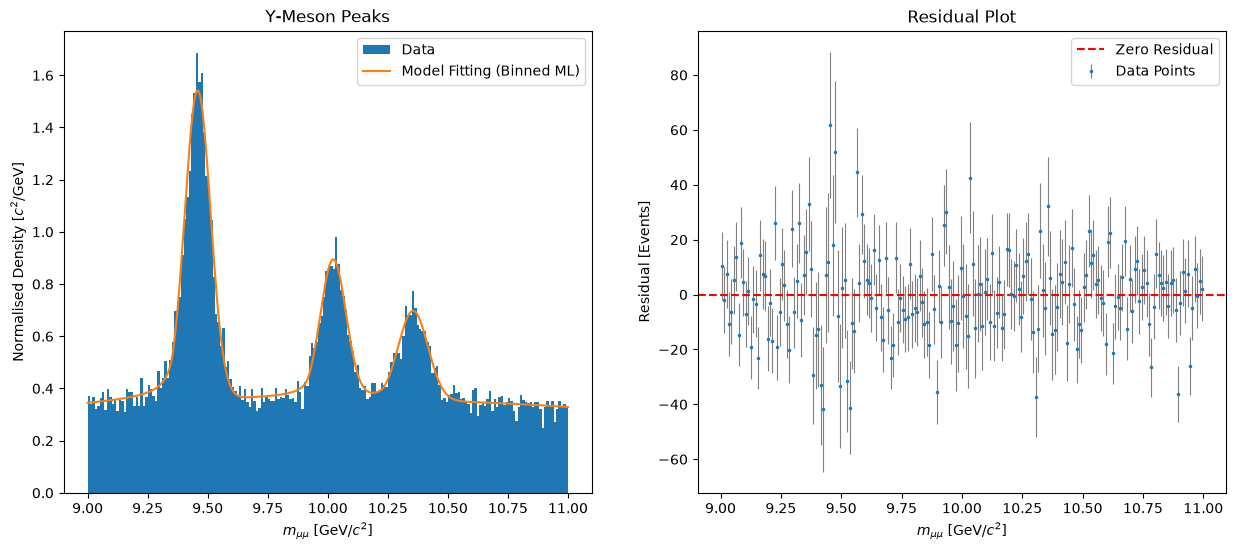

Chi2 value: 219.779
Reduced Chi2: 1.163
Birge Ratio: 1.078


In [42]:
'''
Task 6: Threshold Cut on p_T_mm to produce cleaner signal
Use Chebyshev polynomial instead of exponential background
'''
from iminuit.cost import BinnedNLL
from scipy.special import chebyt

muon_pair_mass = xdata[0]
p_T_mm = xdata[1]
muon_pair_mass = muon_pair_mass[(muon_pair_mass > features_range[0][0]) & (muon_pair_mass < features_range[0][1])]
cut_mass = muon_pair_mass[p_T_mm > 20]

min_mass, max_mass = features_range[0][0],features_range[0][1]
min_mass_1, max_mass_1 = 9.25,9.60
min_mass_2, max_mass_2 = 9.80,10.10
min_mass_3, max_mass_3 = 10.20,10.40

n_bins = 200
counts, bin_edges = np.histogram(cut_mass, bins=n_bins, range=(min_mass, max_mass))
bin_width = (max_mass - min_mass) / n_bins
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
N_tot = len(cut_mass)

alpha = 1.89471
n = 1.09539


def composite_upsilon_cbf_cdf(x,mu_1,sigma_1,mu_2,sigma_2,mu_3,sigma_3,c1,c2,f_1,f_2,f_3):

    def crystal_ball_cdf(x, mu, sigma):
        norm = crystalball.cdf(max_mass, beta=alpha, m=n, loc=mu, scale=sigma) - crystalball.cdf(min_mass, beta=alpha, m=n, loc=mu, scale=sigma)
        return (crystalball.cdf(x, beta=alpha, m=n, loc=mu, scale=sigma) - crystalball.cdf(min_mass, beta=alpha, m=n, loc=mu, scale=sigma)) / norm

    t = (2.0 * x - (max_mass + min_mass)) / (max_mass - min_mass)
    T0 = chebyt(0)
    T1 = chebyt(1)
    T2 = chebyt(2)
    int_T0 = T0.integ()
    int_T1 = T1.integ()
    int_T2 = T2.integ()
    cdf_T0 = int_T0(t) - int_T0(-1.0)
    cdf_T1 = int_T1(t) - int_T1(-1.0)
    cdf_T2 = int_T2(t) - int_T2(-1.0)
    norm_T0 = int_T0(1.0) - int_T0(-1.0)
    norm_T1 = int_T1(1.0) - int_T1(-1.0)
    norm_T2 = int_T2(1.0) - int_T2(-1.0)

    background_num = cdf_T0 + c1*cdf_T1 + c2*cdf_T2
    background_norm = norm_T0 + c1*norm_T1 + c2*norm_T2
    background_cdf = background_num / background_norm
    return f_1*crystal_ball_cdf(x,mu_1,sigma_1) + f_2*crystal_ball_cdf(x,mu_2,sigma_2) + f_3*crystal_ball_cdf(x,mu_3,sigma_3) + (1-f_1-f_2-f_3)*background_cdf



init_params = [9.45, 0.043, 10.02, 0.046, 10.35, 0.04, -0.5, 0.1, 0.12, 0.04, 0.03]
bounds = [(min_mass_1,max_mass_1), (0.01, 1), (min_mass_2,max_mass_2), (0.01, 1), (min_mass_3,max_mass_3), (0.01, 1), (-1,0), (-0.5,0.5), (0.0, 1.0), (0.0, 1.0), (0.0, 1.0)]
cost = BinnedNLL(counts, bin_edges, composite_upsilon_cbf_cdf)
res = Minuit(cost, *init_params)
res.limits = bounds
res.migrad()
res.hesse()
mu_1_fit, sigma_1_fit, mu_2_fit, sigma_2_fit, mu_3_fit, sigma_3_fit, c1_fit, c2_fit, f_1_fit, f_2_fit, f_3_fit = res.values
cov_matrix = np.array(res.covariance)
errors = res.errors
mu_1_err, sigma_1_err, mu_2_err, sigma_2_err, mu_3_err, sigma_3_err, c1_err, c2_err, f_1_err, f_2_err, f_3_err = errors

N_sig_1 = f_1_fit * N_tot
N_sig_1_err = f_1_err * N_tot
N_sig_2 = f_2_fit * N_tot
N_sig_2_err = f_2_err * N_tot
N_sig_3 = f_3_fit * N_tot
N_sig_3_err = f_3_err * N_tot



print(f"Upsilon(1S) Mass (mu_1): {mu_1_fit:.7f} +- {mu_1_err:.7f} GeV/c^2")
print(f"Mass Resolution (sigma_1): {sigma_1_fit:.7f} +- {sigma_1_err:.7f} GeV/c^2")
print(f"Signal Fraction (f_1): {f_1_fit:.7f} +- {f_1_err:.7f}")
print(f"Upsilon(1S) Yield (N_sig_1): {N_sig_1:.0f} +- {N_sig_1_err:.0f} events")
print(f"-----------------------------------------------------------")
print(f"Upsilon(2S) Mass (mu_2): {mu_2_fit:.7f} +- {mu_2_err:.7f} GeV/c^2")
print(f"Mass Resolution (sigma_2): {sigma_2_fit:.7f} +- {sigma_2_err:.7f} GeV/c^2")
print(f"Signal Fraction (f_2): {f_2_fit:.7f} +- {f_2_err:.7f}")
print(f"Upsilon(2S) Yield (N_sig_2): {N_sig_2:.0f} +- {N_sig_2_err:.0f} events")
print(f"-----------------------------------------------------------")
print(f"Upsilon(3S) Mass (mu_3): {mu_3_fit:.7f} +- {mu_3_err:.7f} GeV/c^2")
print(f"Mass Resolution (sigma_3): {sigma_3_fit:.7f} +- {sigma_3_err:.7f} GeV/c^2")
print(f"Signal Fraction (f_3): {f_3_fit:.7f} +- {f_3_err:.7f}")
print(f"Upsilon(3S) Yield (N_sig_3): {N_sig_3:.0f} +- {N_sig_3_err:.0f} events")
print(f"-----------------------------------------------------------")
print(f"Chebyshev 1st (c1): {c1_fit:.7f} +- {c1_err:.7f}")
print(f"Chebyshev 2nd (c2): {c2_fit:.7f} +- {c2_err:.7f}")
print(f"Purity: {f_1_fit+f_2_fit+f_3_fit:.3f}")
print("Minimum counts in any bin:", np.min(counts))
print("Average counts per bin:", np.mean(counts))

fig, (ax1,ax2) = plt.subplots(1,2,figsize=(15,6))

expected_cdf = composite_upsilon_cbf_cdf(bin_edges, *res.values)
expected_counts = np.diff(expected_cdf) * N_tot
residual = counts - expected_counts
yerr = np.sqrt(counts)

xgrid = np.linspace(features_range[0][0],features_range[0][1],1000)
ax1.hist(cut_mass,bins=n_bins,density=True,range=(features_range[0][0],features_range[0][1]),label='Data')
dx=1e-5
pdf_grid = (composite_upsilon_cbf_cdf(xgrid + dx, *res.values) - composite_upsilon_cbf_cdf(xgrid - dx, *res.values)) / (2*dx)
ax1.plot(xgrid,pdf_grid, label='Model Fitting (Binned ML)')
ax1.legend()
ax1.set_xlabel(features_xaxis_label[0])
ax1.set_ylabel(f'Normalised Density {features_yaxis_label_unit[0]}')
ax1.set_title(r'$\Upsilon$-Meson Peaks')

ax2.errorbar(bin_centers, residual, yerr=yerr, fmt="o", markersize=1.5, ecolor="gray", elinewidth=0.8,label='Data Points')
ax2.axhline(0, color="red", linestyle="--",label='Zero Residual')
ax2.set_xlabel(features_xaxis_label[0])
ax2.set_ylabel(f"Residual [Events]")
ax2.legend()
ax2.set_title(r'Residual Plot')
plt.savefig(f'whole_spectrum_fit_binned_{filename[:-4]}.pdf')
plt.show()

chi2 = np.sum(residual**2/expected_counts)
reduced_chi2 = chi2 / (len(counts) - len(init_params))
BR = np.sqrt(reduced_chi2)
print(f'Chi2 value: {chi2:.3f}')
print(f'Reduced Chi2: {reduced_chi2:.3f}')
print(f'Birge Ratio: {BR:.3f}')

Upsilon(1S) Mass (mu_1): 9.4580522 +- 0.0009987 GeV/c^2
Mass Resolution (sigma_1): 0.0536438 +- 0.0010391 GeV/c^2
Signal Fraction (f_1): 0.1685523 +- 0.0027907
Upsilon(1S) Yield (N_sig_1): 7058 +- 117 events
-----------------------------------------------------------
Upsilon(2S) Mass (mu_2): 10.0225024 +- 0.0018183 GeV/c^2
Mass Resolution (sigma_2): 0.0533002 +- 0.0019399 GeV/c^2
Signal Fraction (f_2): 0.0765701 +- 0.0027779
Upsilon(2S) Yield (N_sig_2): 3206 +- 116 events
-----------------------------------------------------------
Upsilon(3S) Mass (mu_3): 10.3553174 +- 0.0027982 GeV/c^2
Mass Resolution (sigma_3): 0.0613520 +- 0.0031705 GeV/c^2
Signal Fraction (f_3): 0.0572618 +- 0.0027825
Upsilon(3S) Yield (N_sig_3): 2398 +- 117 events
-----------------------------------------------------------
Chebyshev 1st (c1): -0.0000000 +- 0.0326199
Chebyshev 2nd (c2): -0.0429719 +- 0.0134607
Purity: 0.302 +- 0.006
-----------------------------------------------------------
Minimum counts in any b

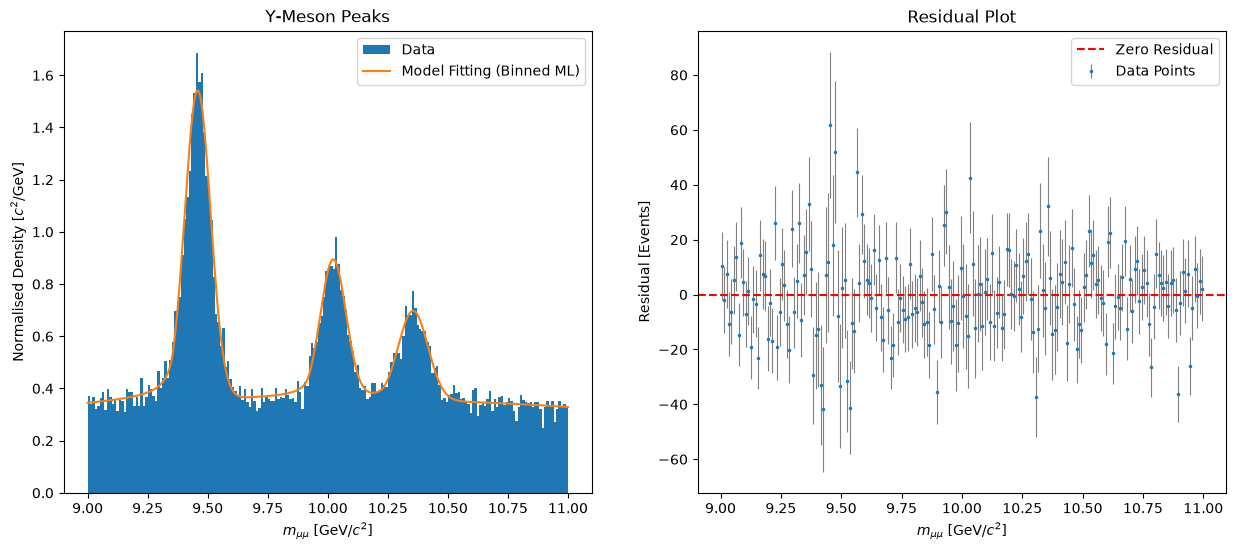

Chi2 value: 219.779
Reduced Chi2: 1.163
Birge Ratio: 1.078


In [43]:
'''
Task 6: Threshold Cut on p_T_mm to produce cleaner signal
Use Chebyshev polynomial instead of exponential background
'''
from iminuit.cost import BinnedNLL
from scipy.special import chebyt

muon_pair_mass = xdata[0]
p_T_mm = xdata[1]
muon_pair_mass = muon_pair_mass[(muon_pair_mass > features_range[0][0]) & (muon_pair_mass < features_range[0][1])]
cut_mass = muon_pair_mass[p_T_mm > 20]

min_mass, max_mass = features_range[0][0],features_range[0][1]
min_mass_1, max_mass_1 = 9.25,9.60
min_mass_2, max_mass_2 = 9.80,10.10
min_mass_3, max_mass_3 = 10.20,10.40

n_bins = 200
counts, bin_edges = np.histogram(cut_mass, bins=n_bins, range=(min_mass, max_mass))
bin_width = (max_mass - min_mass) / n_bins
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])
N_tot = len(cut_mass)

alpha = 1.89471
n = 1.09539


def composite_upsilon_cbf_cdf(x,mu_1,sigma_1,mu_2,sigma_2,mu_3,sigma_3,c1,c2,f_1,f_2,f_3):

    def crystal_ball_cdf(x, mu, sigma):
        norm = crystalball.cdf(max_mass, beta=alpha, m=n, loc=mu, scale=sigma) - crystalball.cdf(min_mass, beta=alpha, m=n, loc=mu, scale=sigma)
        return (crystalball.cdf(x, beta=alpha, m=n, loc=mu, scale=sigma) - crystalball.cdf(min_mass, beta=alpha, m=n, loc=mu, scale=sigma)) / norm

    t = (2.0 * x - (max_mass + min_mass)) / (max_mass - min_mass)
    T0 = chebyt(0)
    T1 = chebyt(1)
    T2 = chebyt(2)
    int_T0 = T0.integ()
    int_T1 = T1.integ()
    int_T2 = T2.integ()
    cdf_T0 = int_T0(t) - int_T0(-1.0)
    cdf_T1 = int_T1(t) - int_T1(-1.0)
    cdf_T2 = int_T2(t) - int_T2(-1.0)
    norm_T0 = int_T0(1.0) - int_T0(-1.0)
    norm_T1 = int_T1(1.0) - int_T1(-1.0)
    norm_T2 = int_T2(1.0) - int_T2(-1.0)

    background_num = cdf_T0 + c1*cdf_T1 + c2*cdf_T2
    background_norm = norm_T0 + c1*norm_T1 + c2*norm_T2
    background_cdf = background_num / background_norm
    return f_1*crystal_ball_cdf(x,mu_1,sigma_1) + f_2*crystal_ball_cdf(x,mu_2,sigma_2) + f_3*crystal_ball_cdf(x,mu_3,sigma_3) + (1-f_1-f_2-f_3)*background_cdf



init_params = [9.45, 0.043, 10.02, 0.046, 10.35, 0.04, -0.5, 0.1, 0.12, 0.04, 0.03]
bounds = [(min_mass_1,max_mass_1), (0.01, 1), (min_mass_2,max_mass_2), (0.01, 1), (min_mass_3,max_mass_3), (0.01, 1), (-1,0), (-0.5,0.5), (0.0, 1.0), (0.0, 1.0), (0.0, 1.0)]
cost = BinnedNLL(counts, bin_edges, composite_upsilon_cbf_cdf)
res = Minuit(cost, *init_params)
res.limits = bounds
res.migrad()
res.hesse()
mu_1_fit, sigma_1_fit, mu_2_fit, sigma_2_fit, mu_3_fit, sigma_3_fit, c1_fit, c2_fit, f_1_fit, f_2_fit, f_3_fit = res.values
cov = np.array(res.covariance)
errors = res.errors
mu_1_err, sigma_1_err, mu_2_err, sigma_2_err, mu_3_err, sigma_3_err, c1_err, c2_err, f_1_err, f_2_err, f_3_err = errors

N_sig_1 = f_1_fit * N_tot
N_sig_1_err = f_1_err * N_tot
N_sig_2 = f_2_fit * N_tot
N_sig_2_err = f_2_err * N_tot
N_sig_3 = f_3_fit * N_tot
N_sig_3_err = f_3_err * N_tot
purity = f_1_fit+f_2_fit+f_3_fit
purity_err = np.sqrt(f_1_err**2 + f_2_err**2 + f_3_err**2 + 2*cov[8][9] + 2*cov[8][10] + 2*cov[9][10])



print(f"Upsilon(1S) Mass (mu_1): {mu_1_fit:.7f} +- {mu_1_err:.7f} GeV/c^2")
print(f"Mass Resolution (sigma_1): {sigma_1_fit:.7f} +- {sigma_1_err:.7f} GeV/c^2")
print(f"Signal Fraction (f_1): {f_1_fit:.7f} +- {f_1_err:.7f}")
print(f"Upsilon(1S) Yield (N_sig_1): {N_sig_1:.0f} +- {N_sig_1_err:.0f} events")
print(f"-----------------------------------------------------------")
print(f"Upsilon(2S) Mass (mu_2): {mu_2_fit:.7f} +- {mu_2_err:.7f} GeV/c^2")
print(f"Mass Resolution (sigma_2): {sigma_2_fit:.7f} +- {sigma_2_err:.7f} GeV/c^2")
print(f"Signal Fraction (f_2): {f_2_fit:.7f} +- {f_2_err:.7f}")
print(f"Upsilon(2S) Yield (N_sig_2): {N_sig_2:.0f} +- {N_sig_2_err:.0f} events")
print(f"-----------------------------------------------------------")
print(f"Upsilon(3S) Mass (mu_3): {mu_3_fit:.7f} +- {mu_3_err:.7f} GeV/c^2")
print(f"Mass Resolution (sigma_3): {sigma_3_fit:.7f} +- {sigma_3_err:.7f} GeV/c^2")
print(f"Signal Fraction (f_3): {f_3_fit:.7f} +- {f_3_err:.7f}")
print(f"Upsilon(3S) Yield (N_sig_3): {N_sig_3:.0f} +- {N_sig_3_err:.0f} events")
print(f"-----------------------------------------------------------")
print(f"Chebyshev 1st (c1): {c1_fit:.7f} +- {c1_err:.7f}")
print(f"Chebyshev 2nd (c2): {c2_fit:.7f} +- {c2_err:.7f}")
print(f"Purity: {purity:.3f} +- {purity_err:.3f}")
print(f"-----------------------------------------------------------")
print("Minimum counts in any bin:", np.min(counts))
print("Average counts per bin:", np.mean(counts))
print(f"-----------------------------------------------------------")
corrs = res.covariance.correlation()
for bg in ["c1", "c2"]:
    for sig in ["mu_1", "sigma_1", "f_1", "mu_2", "sigma_2", "f_2", "mu_3", "sigma_3", "f_3"]:
        print(f"Corr({bg}, {sig}): {corrs[bg, sig]:+.3f}")

fig, (ax1,ax2) = plt.subplots(1,2,figsize=(15,6))

expected_cdf = composite_upsilon_cbf_cdf(bin_edges, *res.values)
expected_counts = np.diff(expected_cdf) * N_tot
residual = counts - expected_counts
yerr = np.sqrt(counts)

xgrid = np.linspace(features_range[0][0],features_range[0][1],1000)
ax1.hist(cut_mass,bins=n_bins,density=True,range=(features_range[0][0],features_range[0][1]),label='Data')
dx=1e-5
pdf_grid = (composite_upsilon_cbf_cdf(xgrid + dx, *res.values) - composite_upsilon_cbf_cdf(xgrid - dx, *res.values)) / (2*dx)
ax1.plot(xgrid,pdf_grid, label='Model Fitting (Binned ML)')
ax1.legend()
ax1.set_xlabel(features_xaxis_label[0])
ax1.set_ylabel(f'Normalised Density {features_yaxis_label_unit[0]}')
ax1.set_title(r'$\Upsilon$-Meson Peaks')

ax2.errorbar(bin_centers, residual, yerr=yerr, fmt="o", markersize=1.5, ecolor="gray", elinewidth=0.8,label='Data Points')
ax2.axhline(0, color="red", linestyle="--",label='Zero Residual')
ax2.set_xlabel(features_xaxis_label[0])
ax2.set_ylabel(f"Residual [Events]")
ax2.legend()
ax2.set_title(r'Residual Plot')
plt.savefig(f'whole_spectrum_fit_binned_{filename[:-4]}.pdf')
plt.show()

chi2 = np.sum(residual**2/expected_counts)
reduced_chi2 = chi2 / (len(counts) - len(init_params))
BR = np.sqrt(reduced_chi2)
print(f'Chi2 value: {chi2:.3f}')
print(f'Reduced Chi2: {reduced_chi2:.3f}')
print(f'Birge Ratio: {BR:.3f}')